# Toy linear penalty model sandbox


In [1]:
# Import matplotlib and numpy - helpful Python libraries for scientific computing
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.patches as patches
from matplotlib import ticker
from math import pi
from decimal import Decimal

from scipy import optimize

In [2]:
# Define parameters
D_min = 2.73
D_max = 10
M_l = 1
M_u = 1

# Assuming one dose point and one dwell position
dose_rate = 0.1 # Gy/s
dwell_times = np.array([x for x in range(0,501)]) # s

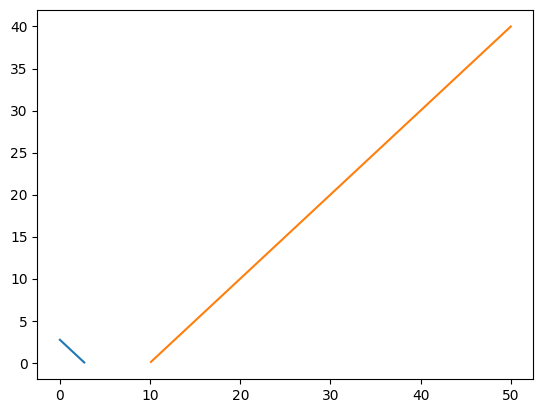

In [3]:
# Plot cost function
fig1, ax1 = plt.subplots()
doses = dose_rate*dwell_times

# lower bound
doses_l = doses[doses < D_min]
cost_l = M_l*(D_min - doses_l)

# upper bound
doses_u = doses[doses > D_max]
cost_u = M_u*(doses_u - D_max)

ax1.plot(doses_l, cost_l)
ax1.plot(doses_u, cost_u)

In [4]:
c = [1, 1]
A = [[-1, 0], [0, -1]]

obj_funcs = np.array([])
cost = np.inf # initialize cost function value to infinity
opt_index = 0 # initialize optimal index

for i in range(len(dwell_times)):
    # calculate upper bound for iteration
    b = [M_l*(D_min - dose_rate*dwell_times[i]), M_u*(dose_rate*dwell_times[i] - D_max)]

    # run optimization
    result = optimize.linprog(c, A_ub=A, b_ub=b)
    if result.fun < cost:
        opt_index = i
        cost = result.fun

    obj_funcs = np.append(obj_funcs, result.fun)

print(opt_index)
print(obj_funcs[opt_index])
print(dwell_times[opt_index])
# note that the optimal dwell time corresponds to D_min - this is the first dose encountered with cost = 0, so it's giving the expected result

28
7.27
28


This works, but I don't think I'm implementing the model correctly. It would probably take up way too much computational time to iterate over this for multiple dwell psoitions and multiple dose points. Plus, it might return multiple optimal objective functions. 